# Bài 2 (Trang 15-16): Phân lớp dữ liệu Adult Income
**Sinh viên:** Trần Nhất Long - 6451071042

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn.naive_bayes import GaussianNB
from sklearn import metrics

print("Trần Nhất Long - 6451071042")

Trần Nhất Long - 6451071042


## Câu 1: Nhập dữ liệu đầu vào và thống kê số lượng dữ liệu huấn luyện, kiểm thử

In [2]:
print("Trần Nhất Long - 6451071042")
train_raw = pd.read_csv("adult.data.csv", skipinitialspace=True, na_values="?")
test_raw = pd.read_csv("adult.test.csv", skipinitialspace=True, na_values="?")

print("Số lượng dữ liệu huấn luyện (ban đầu):", len(train_raw))
print("Số lượng dữ liệu kiểm thử (ban đầu):", len(test_raw))
print("Kích thước tập huấn luyện:", train_raw.shape)
print("Kích thước tập kiểm thử:", test_raw.shape)
train_raw.head()

Trần Nhất Long - 6451071042
Số lượng dữ liệu huấn luyện (ban đầu): 32561
Số lượng dữ liệu kiểm thử (ban đầu): 16281
Kích thước tập huấn luyện: (32561, 15)
Kích thước tập kiểm thử: (16281, 14)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


## Câu 2: Tiền xử lý dữ liệu
- Xóa các dòng chứa dữ liệu trống (`?`)
- Xóa cột `fnlwgt` trong dữ liệu huấn luyện (nếu có) vì không có trong dữ liệu kiểm thử
- Nối dữ liệu huấn luyện và kiểm thử lại thành biến `data`

In [3]:
print("Trần Nhất Long - 6451071042")
train_clean = train_raw.dropna().copy()
test_clean = test_raw.dropna().copy()

if "fnlwgt" in train_clean.columns:
    train_clean = train_clean.drop("fnlwgt", axis=1)
if "fnlwgt" in test_clean.columns:
    test_clean = test_clean.drop("fnlwgt", axis=1)

n_train = len(train_clean)
n_test = len(test_clean)
print(f"Number of training data: {n_train}")
print(f"Number of test data: {n_test}")

data = pd.concat([train_clean, test_clean], ignore_index=True)
data.info()

Trần Nhất Long - 6451071042
Number of training data: 30162
Number of test data: 15060
<class 'pandas.DataFrame'>
RangeIndex: 45222 entries, 0 to 45221
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             45222 non-null  int64
 1   workclass       45222 non-null  str  
 2   education       45222 non-null  str  
 3   education-num   45222 non-null  int64
 4   marital-status  45222 non-null  str  
 5   occupation      45222 non-null  str  
 6   relationship    45222 non-null  str  
 7   race            45222 non-null  str  
 8   sex             45222 non-null  str  
 9   capital-gain    45222 non-null  int64
 10  capital-loss    45222 non-null  int64
 11  hours-per-week  45222 non-null  int64
 12  native-country  45222 non-null  str  
 13  income          45222 non-null  str  
dtypes: int64(5), str(9)
memory usage: 8.4 MB


## Câu 3: Khảo sát độ tương đồng giữa các cột bằng công thức Pearson

Trần Nhất Long - 6451071042


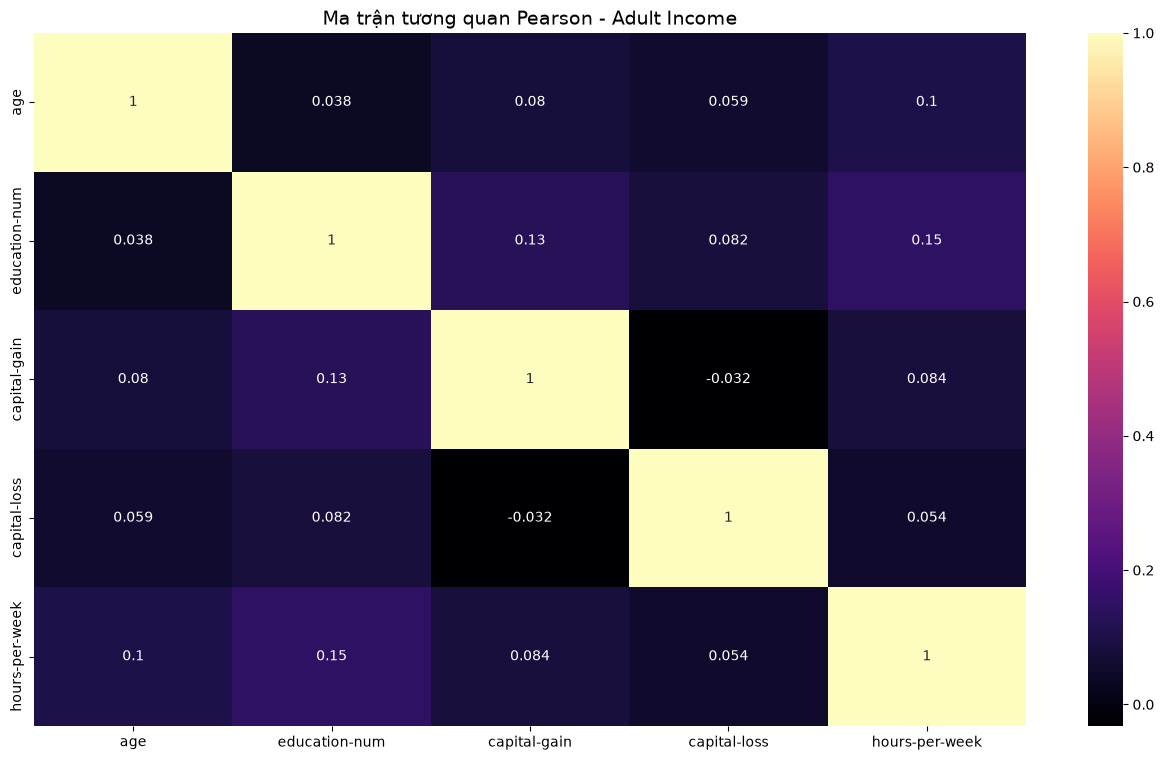

Nhận xét: Giá trị tương quan giữa các cặp thuộc tính số đều rất thấp (tối đa ~0.15), nên không cần loại bỏ cột nào.


In [4]:
print("Trần Nhất Long - 6451071042")
plt.figure(figsize=(16, 9))
corr_matrix = data.corr(method="pearson", numeric_only=True)
sns.heatmap(corr_matrix, annot=True, cmap="magma")
plt.title("Ma trận tương quan Pearson - Adult Income", fontsize=14)
plt.show()
print("Nhận xét: Giá trị tương quan giữa các cặp thuộc tính số đều rất thấp (tối đa ~0.15), nên không cần loại bỏ cột nào.")

## Câu 4: Tách các cột dữ liệu thành thuộc tính đầu vào (`features`) và thuộc tính quyết định (`labels`)

In [5]:
print("Trần Nhất Long - 6451071042")
features = data.drop("income", axis=1)
labels = data["income"]
print("Kích thước features:", features.shape)
print("Kích thước labels:", labels.shape)
print("Phân bố nhãn:")
print(labels.value_counts())

Trần Nhất Long - 6451071042
Kích thước features: (45222, 13)
Kích thước labels: (45222,)
Phân bố nhãn:
income
<=50K    34014
>50K     11208
Name: count, dtype: int64


## Câu 5: Chuyển đổi các cột không phải dạng số về dạng one-hot vector

In [6]:
print("Trần Nhất Long - 6451071042")
non_numeric_cols = features.select_dtypes(exclude=["int64", "float64"]).columns
print("Các cột không phải dạng số:", list(non_numeric_cols))

features_onehot = pd.get_dummies(features, columns=non_numeric_cols)
print("Kích thước sau khi one-hot encoding:", features_onehot.shape)
features_onehot.head()

Trần Nhất Long - 6451071042
Các cột không phải dạng số: ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']
Kích thước sau khi one-hot encoding: (45222, 103)


,age,education-num,capital-gain,capital-loss,hours-per-week,workclass_Federal-gov,workclass_Local-gov,workclass_Private,workclass_Self-emp-inc,workclass_Self-emp-not-inc,...,native-country_Portugal,native-country_Puerto-Rico,native-country_Scotland,native-country_South,native-country_Taiwan,native-country_Thailand,native-country_Trinadad&Tobago,native-country_United-States,native-country_Vietnam,native-country_Yugoslavia
0,39,13,2174,0,40,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
1,50,13,0,0,13,False,False,False,False,True,...,False,False,False,False,False,False,False,True,False,False
2,38,9,0,0,40,False,False,True,False,False,...,False,False,False,False,False,False,False,True,False,False
3,53,7,0,0,40,False,False,True,False,False,...,False,False,False,False,False,False,False,True,False,False
4,28,13,0,0,40,False,False,True,False,False,...,False,False,False,False,False,False,False,False,False,False


## Câu 6: Tách các dòng dữ liệu lại thành phần huấn luyện và kiểm thử như ban đầu

In [7]:
print("Trần Nhất Long - 6451071042")
X_train = features_onehot[:n_train]
X_test = features_onehot[n_train:]
y_train = labels[:n_train]
y_test = labels[n_train:]

print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_test:", X_test.shape, "| y_test:", y_test.shape)

Trần Nhất Long - 6451071042
X_train: (30162, 103) | y_train: (30162,)
X_test: (15060, 103) | y_test: (15060,)


## Câu 7: Xây dựng cây ID3 (`criterion='entropy'`), đánh giá bằng ma trận nhầm lẫn và biểu diễn cây

Trần Nhất Long - 6451071042


Accuracy (ID3): 0.8175298804780876
Report (ID3):
               precision    recall  f1-score   support

       <=50K       0.88      0.88      0.88     11360
        >50K       0.63      0.62      0.62      3700

    accuracy                           0.82     15060
   macro avg       0.75      0.75      0.75     15060
weighted avg       0.82      0.82      0.82     15060



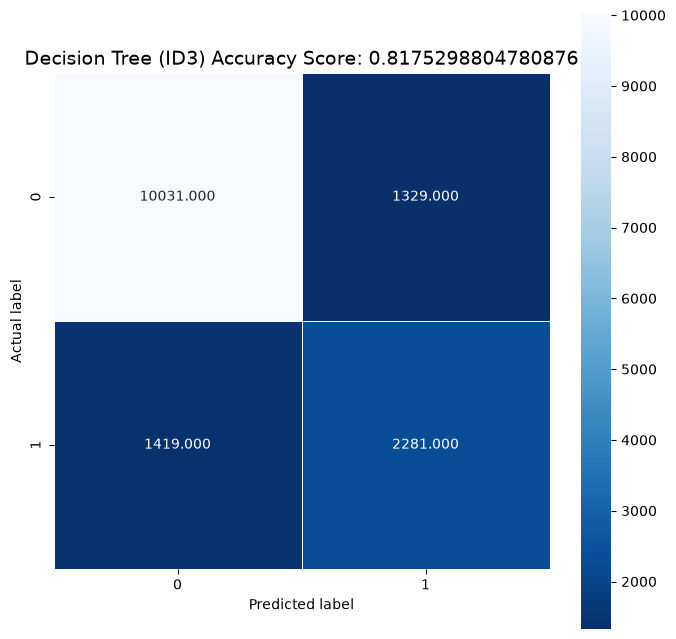

Độ sâu cây ID3 đầy đủ: 51, số nút lá: 5327
Biểu diễn cây ID3 (hiển thị 4 tầng đầu để trực quan):


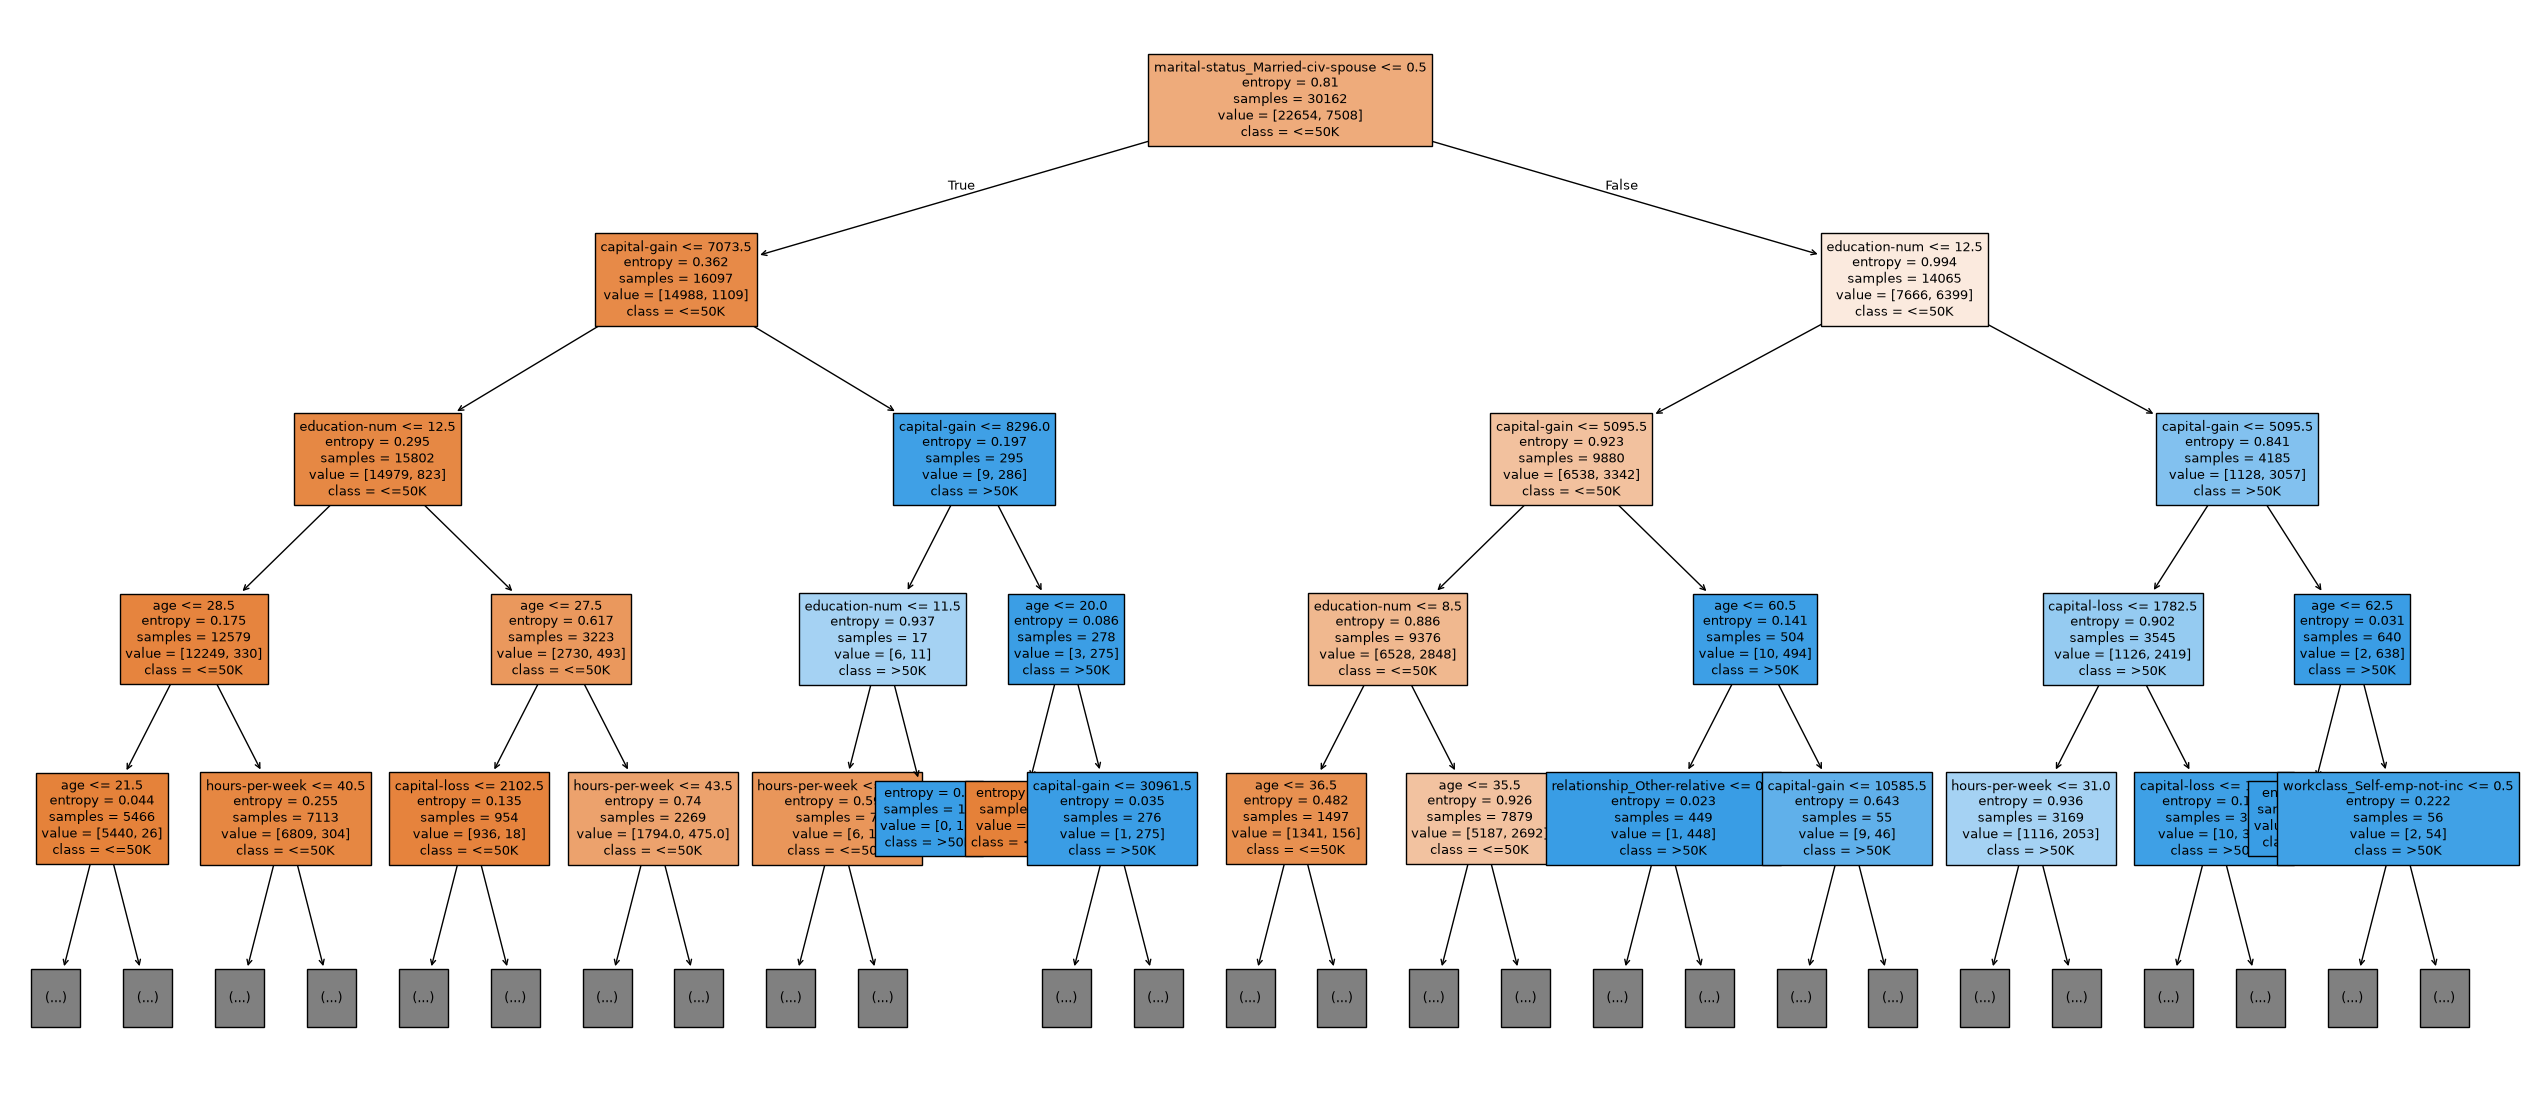

In [8]:
print("Trần Nhất Long - 6451071042")
clf_id3 = tree.DecisionTreeClassifier(criterion="entropy", random_state=0)
clf_id3.fit(X_train, y_train)
id3_pred = clf_id3.predict(X_test)

id3_score = metrics.accuracy_score(y_test, id3_pred)
print("Accuracy (ID3):", id3_score)
print("Report (ID3):\n", metrics.classification_report(y_test, id3_pred))

id3_cm = metrics.confusion_matrix(y_test, id3_pred)
plt.figure(figsize=(8, 8))
sns.heatmap(id3_cm, annot=True, fmt=".3f", linewidths=0.5, square=True, cmap="Blues_r")
plt.ylabel("Actual label")
plt.xlabel("Predicted label")
plt.title(f"Decision Tree (ID3) Accuracy Score: {id3_score}", size=14)
plt.show()

print(f"Độ sâu cây ID3 đầy đủ: {clf_id3.get_depth()}, số nút lá: {clf_id3.get_n_leaves()}")
print("Biểu diễn cây ID3 (hiển thị 4 tầng đầu để trực quan):")
fig, ax = plt.subplots(figsize=(32, 14))
tree.plot_tree(
    clf_id3,
    feature_names=list(features_onehot.columns),
    class_names=[str(c) for c in clf_id3.classes_],
    filled=True,
    fontsize=9,
    max_depth=4,
)
plt.savefig("decision_tree_id3_adult.png", dpi=100, bbox_inches="tight")
plt.show()

## Câu 8: Xây dựng cây CART (`criterion='gini'`), đánh giá bằng ma trận nhầm lẫn và biểu diễn cây

Trần Nhất Long - 6451071042


Accuracy (CART): 0.8122841965471448
Report (CART):
               precision    recall  f1-score   support

       <=50K       0.87      0.88      0.88     11360
        >50K       0.62      0.60      0.61      3700

    accuracy                           0.81     15060
   macro avg       0.75      0.74      0.74     15060
weighted avg       0.81      0.81      0.81     15060



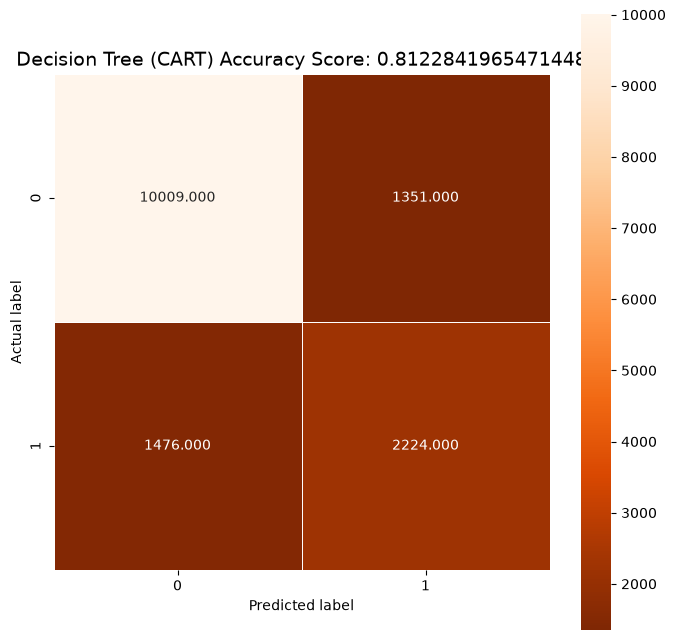

Độ sâu cây CART đầy đủ: 46, số nút lá: 5331
Biểu diễn cây CART (hiển thị 4 tầng đầu để trực quan):


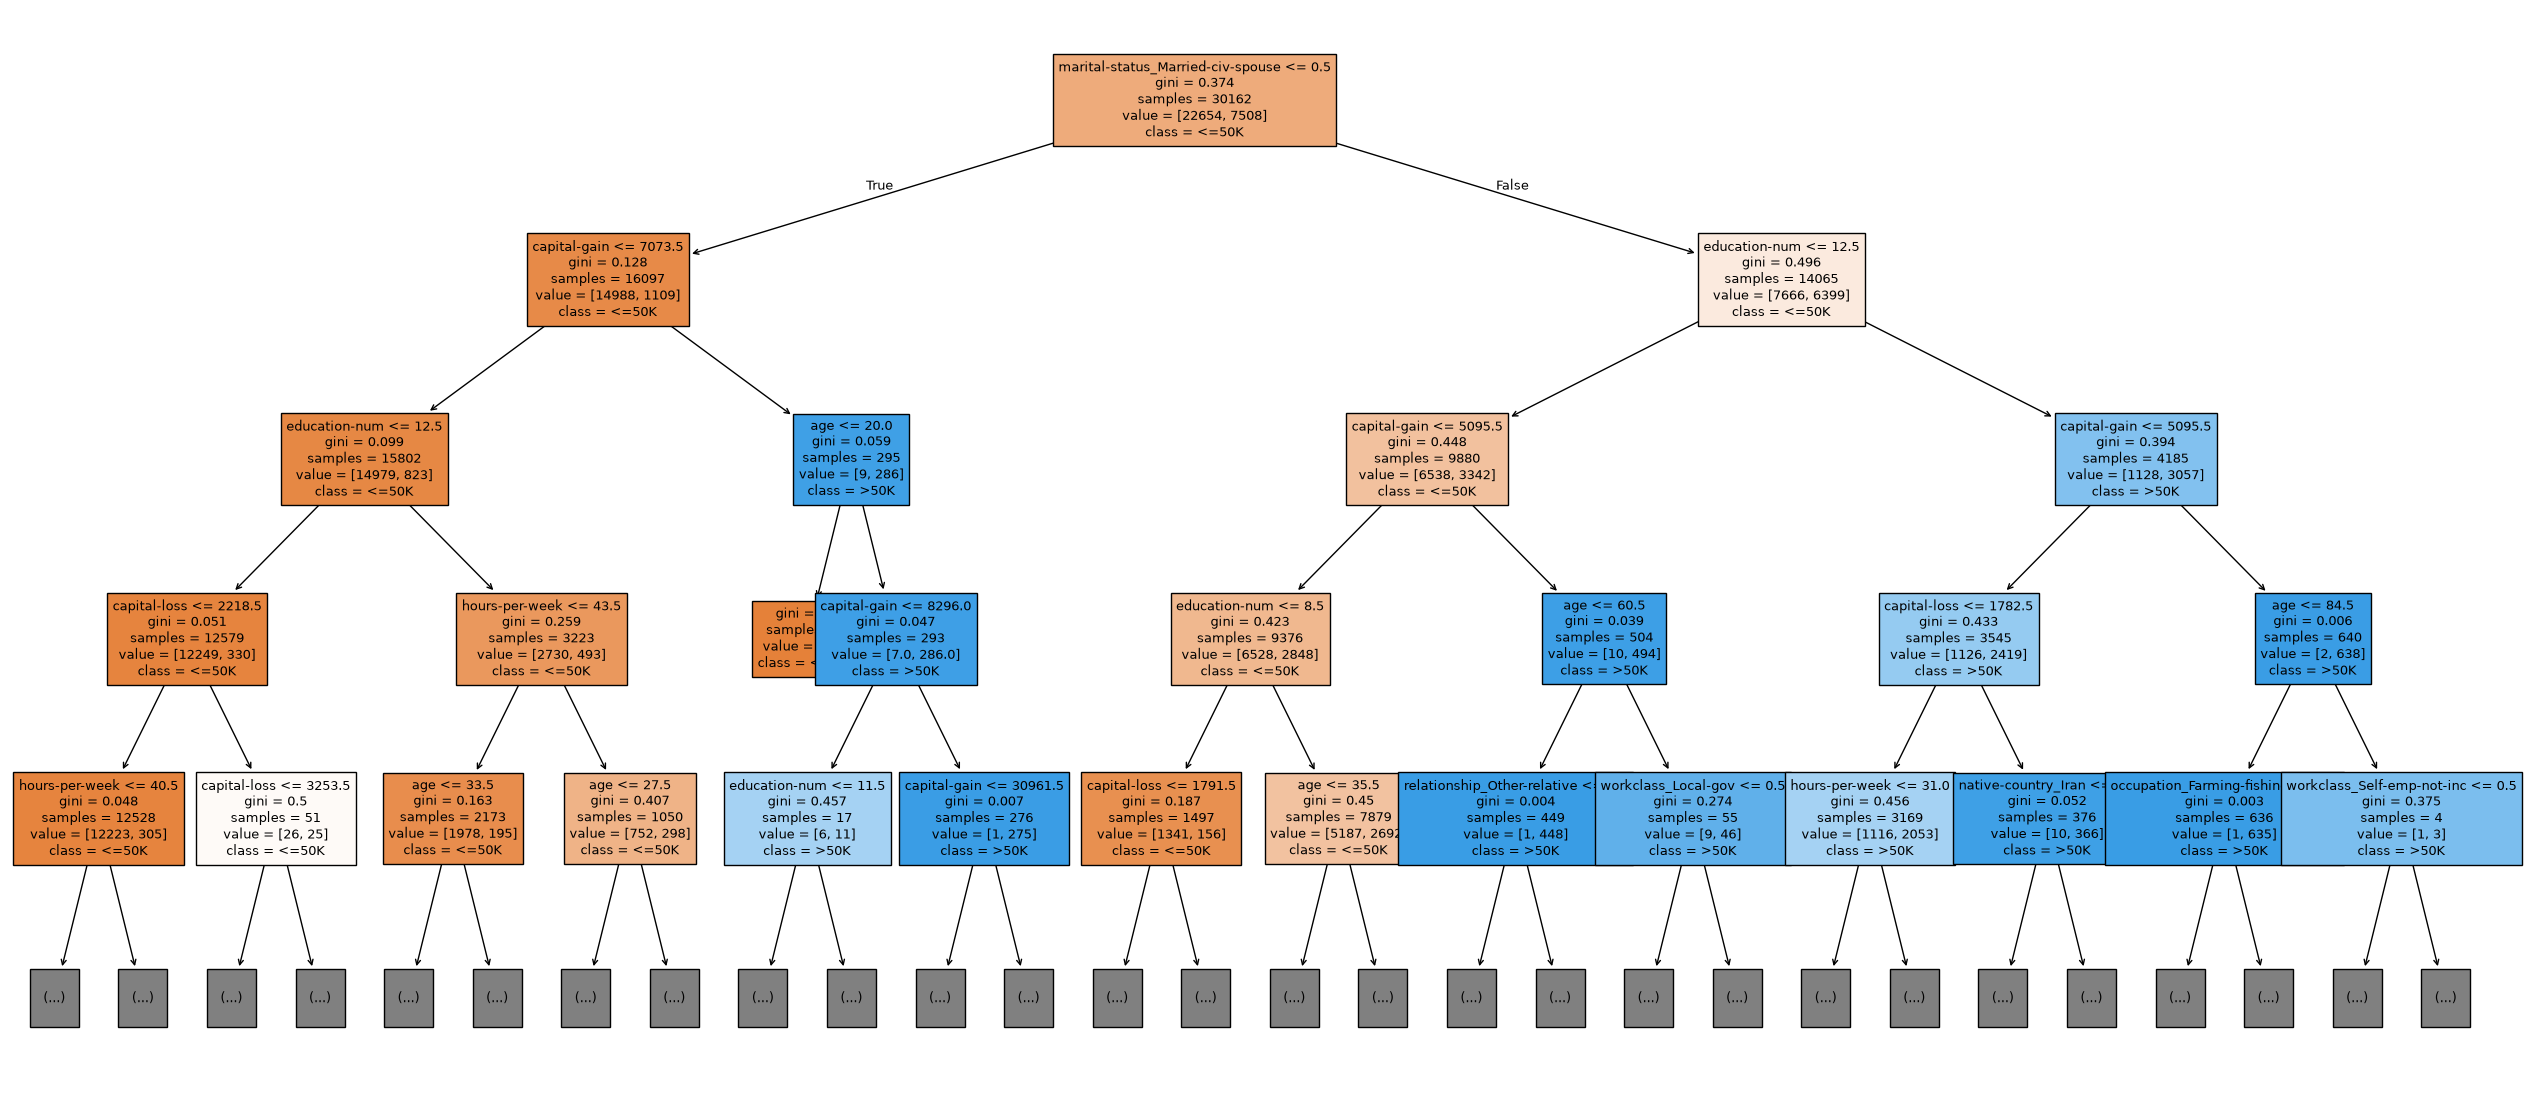

In [9]:
print("Trần Nhất Long - 6451071042")
clf_cart = tree.DecisionTreeClassifier(criterion="gini", random_state=0)
clf_cart.fit(X_train, y_train)
cart_pred = clf_cart.predict(X_test)

cart_score = metrics.accuracy_score(y_test, cart_pred)
print("Accuracy (CART):", cart_score)
print("Report (CART):\n", metrics.classification_report(y_test, cart_pred))

cart_cm = metrics.confusion_matrix(y_test, cart_pred)
plt.figure(figsize=(8, 8))
sns.heatmap(cart_cm, annot=True, fmt=".3f", linewidths=0.5, square=True, cmap="Oranges_r")
plt.ylabel("Actual label")
plt.xlabel("Predicted label")
plt.title(f"Decision Tree (CART) Accuracy Score: {cart_score}", size=14)
plt.show()

print(f"Độ sâu cây CART đầy đủ: {clf_cart.get_depth()}, số nút lá: {clf_cart.get_n_leaves()}")
print("Biểu diễn cây CART (hiển thị 4 tầng đầu để trực quan):")
fig, ax = plt.subplots(figsize=(32, 14))
tree.plot_tree(
    clf_cart,
    feature_names=list(features_onehot.columns),
    class_names=[str(c) for c in clf_cart.classes_],
    filled=True,
    fontsize=9,
    max_depth=4,
)
plt.savefig("decision_tree_cart_adult.png", dpi=100, bbox_inches="tight")
plt.show()

## Câu 9: Xây dựng mô hình Naïve Bayes (`GaussianNB`) và kiểm tra kết quả

Trần Nhất Long - 6451071042
Accuracy (Naïve Bayes): 0.8029216467463479


Report (Naïve Bayes):
               precision    recall  f1-score   support

       <=50K       0.93      0.80      0.86     11360
        >50K       0.57      0.82      0.67      3700

    accuracy                           0.80     15060
   macro avg       0.75      0.81      0.76     15060
weighted avg       0.84      0.80      0.81     15060



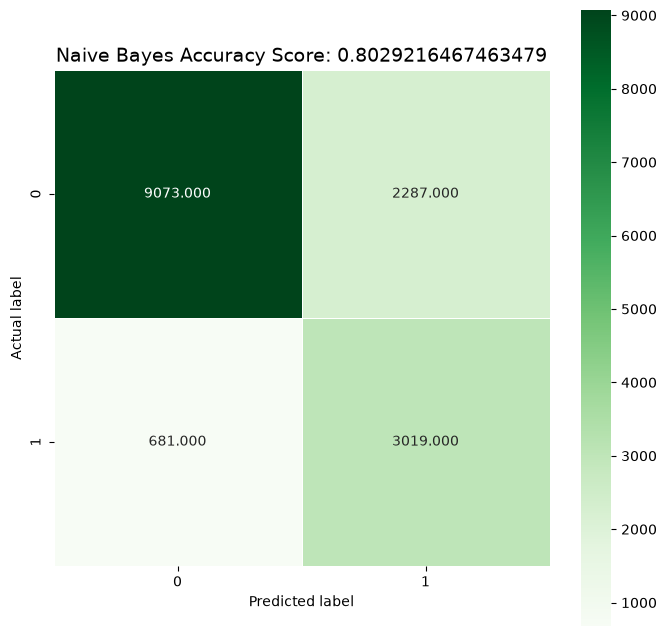

In [10]:
print("Trần Nhất Long - 6451071042")
gnb = GaussianNB()
bayes_pred = gnb.fit(X_train, y_train).predict(X_test)

bayes_score = metrics.accuracy_score(y_test, bayes_pred)
print("Accuracy (Naïve Bayes):", bayes_score)
print("Report (Naïve Bayes):\n", metrics.classification_report(y_test, bayes_pred))

bayes_cm = metrics.confusion_matrix(y_test, bayes_pred)
plt.figure(figsize=(8, 8))
sns.heatmap(bayes_cm, annot=True, fmt=".3f", linewidths=0.5, square=True, cmap="Greens")
plt.ylabel("Actual label")
plt.xlabel("Predicted label")
plt.title(f"Naive Bayes Accuracy Score: {bayes_score}", size=14)
plt.show()

## Câu 10: So sánh kết quả của các mô hình

Trần Nhất Long - 6451071042


                 Mô hình  Accuracy  Precision (Macro)  Recall (Macro)  F1-score (Macro)  F1-score (Weighted)
           ID3 (Entropy)  0.817530           0.753963        0.749749          0.751802             0.816767
             CART (Gini)  0.812284           0.746791        0.741078          0.743831             0.811185
Naïve Bayes (GaussianNB)  0.802922           0.749581        0.807313          0.764936             0.812998


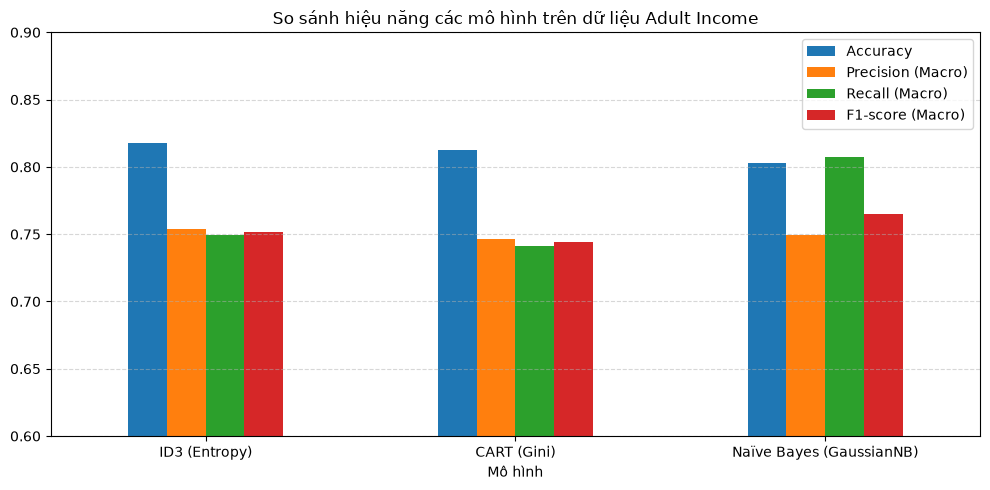


Nhận xét:
- Hai mô hình cây quyết định (ID3 và CART) đạt Accuracy cao hơn (~81.75% và ~81.23%) so với Naïve Bayes (~80.29%).
- Naïve Bayes có Recall lớp >50K cao hơn (~0.82), nhưng Precision lớp >50K thấp hơn (~0.57) dẫn đến nhiều dự đoán nhầm từ <=50K sang >50K.
- ID3 nhỉnh hơn nhẹ so với CART về Accuracy trên tập Adult Income.


In [11]:
print("Trần Nhất Long - 6451071042")
results = []
for name, pred in [("ID3 (Entropy)", id3_pred), ("CART (Gini)", cart_pred), ("Naïve Bayes (GaussianNB)", bayes_pred)]:
    results.append({
        "Mô hình": name,
        "Accuracy": metrics.accuracy_score(y_test, pred),
        "Precision (Macro)": metrics.precision_score(y_test, pred, average="macro"),
        "Recall (Macro)": metrics.recall_score(y_test, pred, average="macro"),
        "F1-score (Macro)": metrics.f1_score(y_test, pred, average="macro"),
        "F1-score (Weighted)": metrics.f1_score(y_test, pred, average="weighted"),
    })

df_compare = pd.DataFrame(results)
print(df_compare.to_string(index=False))

df_compare.set_index("Mô hình")[["Accuracy", "Precision (Macro)", "Recall (Macro)", "F1-score (Macro)"]].plot(
    kind="bar", figsize=(10, 5), ylim=(0.6, 0.9)
)
plt.title("So sánh hiệu năng các mô hình trên dữ liệu Adult Income")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

print("\nNhận xét:")
print("- Hai mô hình cây quyết định (ID3 và CART) đạt Accuracy cao hơn (~81.75% và ~81.23%) so với Naïve Bayes (~80.29%).")
print("- Naïve Bayes có Recall lớp >50K cao hơn (~0.82), nhưng Precision lớp >50K thấp hơn (~0.57) dẫn đến nhiều dự đoán nhầm từ <=50K sang >50K.")
print("- ID3 nhỉnh hơn nhẹ so với CART về Accuracy trên tập Adult Income.")